Imports:

In [1]:
import os
import requests
import zipfile
import pandas as pd
from tqdm import tqdm
import sys
sys.path.append("../src")
from ais_to_parquet_group_by_type import fn
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

This cell fetches data (only run if the data hasn't been loaded yet).

In [2]:
# --- Folder setup ---
RAW_DATA_DIR = "../data/raw"
os.makedirs(RAW_DATA_DIR, exist_ok=True)

# --- Define data source ---
website = "http://aisdata.ais.dk/"
# one week of AIS data files
filenames = ["aisdk-2025-02-27.zip", "aisdk-2025-02-28.zip", "aisdk-2025-03-01.zip", "aisdk-2025-03-02.zip", "aisdk-2025-03-03.zip", "aisdk-2025-03-04.zip", "aisdk-2025-03-05.zip"]
urls = [website + fname for fname in filenames]
target_paths = [os.path.join(RAW_DATA_DIR, fname) for fname in filenames]

# --- Streamed download with progress bar ---
for url, zip_path in zip(urls, target_paths):
    print(f"⬇️ Downloading {url} ...")
    response = requests.get(url, stream=True)
    response.raise_for_status()

    # Total size in bytes.
    total_size = int(response.headers.get("content-length", 0))
    block_size = 1024  # 1 KB

    tqdm_bar = tqdm(total=total_size, unit="iB", unit_scale=True)

    with open(zip_path, "wb") as f:
        for data in response.iter_content(block_size):
            tqdm_bar.update(len(data))
            f.write(data)
    tqdm_bar.close()

    if total_size != 0 and tqdm_bar.n != total_size:
        print("⚠️ Download may be incomplete.")
    else:
        print(f"✅ ZIP file downloaded to {zip_path}")

    # --- Extract ZIP ---
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(RAW_DATA_DIR)
    print(f"📦 Extracted files to {RAW_DATA_DIR}")

⬇️ Downloading http://aisdata.ais.dk/aisdk-2025-02-27.zip ...


  4%|▍         | 25.6M/579M [00:32<20:12, 457kiB/s]   

KeyboardInterrupt: 

  4%|▍         | 25.7M/579M [00:49<20:12, 457kiB/s]

In [5]:
# --- Folder setup ---
RAW_DATA_DIR = "../data/raw"
os.makedirs(RAW_DATA_DIR, exist_ok=True)

# --- Find and load CSV(s) ---
csv_files = [f for f in os.listdir(RAW_DATA_DIR) if f.endswith(".csv")]
print(f"Found CSV files: {csv_files}")

# if csv_files:
#     csv_path = os.path.join(RAW_DATA_DIR, csv_files[0])
#     df = pd.read_csv(csv_path)
#     print(f"✅ Loaded {csv_files[0]} with shape {df.shape}")
#     display(df.head())
# else:
#     print("⚠️ No CSV files found after extraction.")

Found CSV files: ['aisdk-2025-02-27.csv', 'aisdk-2025-02-28.csv']


next objective: apply the preprocessing script & delete unused columns

In [6]:
# --- Folder setup ---
RAW_DATA_DIR = "../data/raw"
os.makedirs(RAW_DATA_DIR, exist_ok=True)

# Choose input and output paths
for csv_file in csv_files:
    print(f"Converting {csv_file} to Parquet...")
    input_csv = os.path.join(RAW_DATA_DIR, csv_files[0])
    output_dir = "../data/processed/" + csv_file.replace(".csv", "")
    print(f"Processing {input_csv} ...")
    fn(input_csv, output_dir)
    print(f"✅ Conversion complete. Parquet data stored in {output_dir}")

Converting aisdk-2025-02-27.csv to Parquet...
Processing ../data/raw\aisdk-2025-02-27.csv ...
Writing data for ship type 'Undefined' to ../data/processed/aisdk-2025-02-27/Undefined ...
Writing data for ship type 'Pilot' to ../data/processed/aisdk-2025-02-27/Pilot ...
Writing data for ship type 'Passenger' to ../data/processed/aisdk-2025-02-27/Passenger ...
Writing data for ship type 'Fishing' to ../data/processed/aisdk-2025-02-27/Fishing ...
Writing data for ship type 'HSC' to ../data/processed/aisdk-2025-02-27/HSC ...
Writing data for ship type 'Other' to ../data/processed/aisdk-2025-02-27/Other ...
Writing data for ship type 'Tug' to ../data/processed/aisdk-2025-02-27/Tug ...
Writing data for ship type 'Cargo' to ../data/processed/aisdk-2025-02-27/Cargo ...
Writing data for ship type 'SAR' to ../data/processed/aisdk-2025-02-27/SAR ...
Writing data for ship type 'Tanker' to ../data/processed/aisdk-2025-02-27/Tanker ...
Writing data for ship type 'Pleasure' to ../data/processed/aisdk-2

✅ Loaded 13613932 AIS points across 1346 vessels
Selected MMSIs: [257071710, 220333000, 219670000]


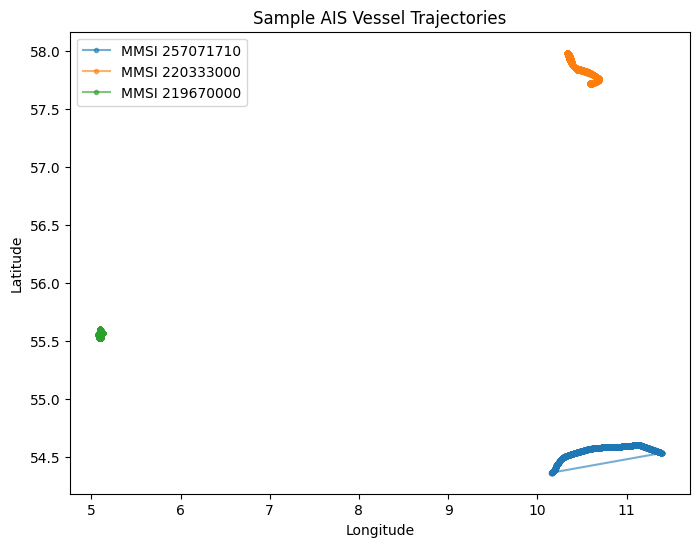

In [7]:
# Path to your processed data
PROCESSED_DIR = "../data/processed"

# Load full dataset (or a subset if large)
dataset = pq.ParquetDataset(PROCESSED_DIR)
df = dataset.read().to_pandas()

print(f"✅ Loaded {len(df)} AIS points across {df['MMSI'].nunique()} vessels")

# Select a few random MMSIs (vessels)
sample_mmsis = df["MMSI"].drop_duplicates().sample(3)
print("Selected MMSIs:", list(sample_mmsis))

plt.figure(figsize=(8, 6))
for mmsi in sample_mmsis:
    sub = df[df["MMSI"] == mmsi]
    plt.plot(sub["Longitude"], sub["Latitude"], marker='.', linestyle='-', alpha=0.6, label=f"MMSI {mmsi}")

plt.title("Sample AIS Vessel Trajectories")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.show()